# 指数型分布族はなぜ統計・機械学習で重要なのか

## 概要

指数型分布族は、ベルヌーイ分布、ポアソン分布、正規分布などを共通の式で表す分布の集まりである。「指数分布」という一つの分布とは異なる。この記事では、平均と分散の計算、十分統計量、最尤推定、ベイズ更新、回帰モデルとの関係を数式とPythonで確認する。

### 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、SymPy、Matplotlibを使う。セルを上から実行すると、図を `104_nb_files` にSVG形式で保存する。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import sys
from base64 import b64encode
from io import BytesIO
from pathlib import Path
from pprint import pprint
from importlib.metadata import version

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy import stats
from scipy.optimize import minimize
from scipy.special import expit, gammaln
from IPython.display import Math, display

assert sys.version_info[:3] == (3, 14, 6), "Python 3.14.6を選択する"
print("実行環境: wa-src(3.14.6)")
print(f"Python: {sys.version.split()[0]}")
pprint({name: version(name) for name in ("numpy", "scipy", "sympy", "matplotlib")})

# Notebookのフォルダーとリポジトリ直下のどちらからも実行できる。
relative_dir = Path("rec/Interdisciplinarity/104")
notebook_dir = relative_dir if relative_dir.is_dir() else Path.cwd()
image_dir = notebook_dir / "104_nb_files"
image_dir.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロを残して、有効数字3桁で表示する。"""
    return "0" if value == 0 else format(float(value), "#.3g").removesuffix(".")


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "svg.hashsalt": "104"})


def save_svg(fig, filename, integer_x=False):
    """目盛りを整え、SVGを保存して出力欄にも表示する。"""
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(
            lambda x, pos: f"{x:.0f}" if integer_x else sig3(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, pos: sig3(y)))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=integer_x))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.grid(alpha=0.200)
    path = image_dir / filename
    fig.savefig(path, format="svg", bbox_inches="tight", metadata={"Date": None})
    # 未信頼のNotebookでも図を表示できるよう、PNGデータを同梱する。
    # ファイルとして保存するのはSVGだけである。
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    plt.close(fig)
    display({"image/svg+xml": path.read_text(),
             "image/png": b64encode(buffer.getvalue()).decode("ascii")}, raw=True)

実行環境: wa-src(3.14.6)
Python: 3.14.6
{'matplotlib': '3.11.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'sympy': '1.14.0'}


## 1. 分布を共通の形で書く

まず自然パラメータが1個の場合を考える。$T(x)$は統計量、$h(x)$はパラメータに依存しない因子である。

<div>

$$p(x;\eta)=h(x)\exp\{\eta T(x)-A(\eta)\}$$

</div>

離散分布の正規化条件から、対数分配関数$A$が決まる。

$$
1=e^{-A(\eta)}\sum_xh(x)e^{\eta T(x)}
\quad\Rightarrow\quad
A(\eta)=\log\sum_xh(x)e^{\eta T(x)}.
$$

連続分布では和を積分に置き換える。以下は台がパラメータに依存せず、自然パラメータ空間の内部で微分と和・積分を交換できる場合を扱う。

| 分布 | $\eta$ | $T(x)$ | $A(\eta)$ | $h(x)$ |
| --- | --- | --- | --- | --- |
| ベルヌーイ | $\log\frac{q}{1-q}$ | $x$ | $\log(1+e^\eta)$ | $1$ |
| ポアソン | $\log\lambda$ | $x$ | $e^\eta$ | $1/x!$ |
| 正規（分散1） | $\mu$ | $x$ | $\eta^2/2$ | $e^{-x^2/2}/\sqrt{2\pi}$ |

台は順に$\{0,1\}$、非負整数、実数全体であり、$\lambda>0$、$\mu\in\mathbb R$とする。

例えば、成功確率$0<q<1$のベルヌーイ分布を変形すると、

$$
\begin{aligned}
q^x(1-q)^{1-x}
&=\exp\{x\log q+(1-x)\log(1-q)\}\\
&=\exp\{x\log[q/(1-q)]+\log(1-q)\},\\
e^\eta&=q/(1-q),\quad q=e^\eta/(1+e^\eta),\\
\log(1-q)&=-\log(1+e^\eta)
\end{aligned}
$$

となり、表の形が得られる。図1は3種類の分布を同じ形から計算した結果である。

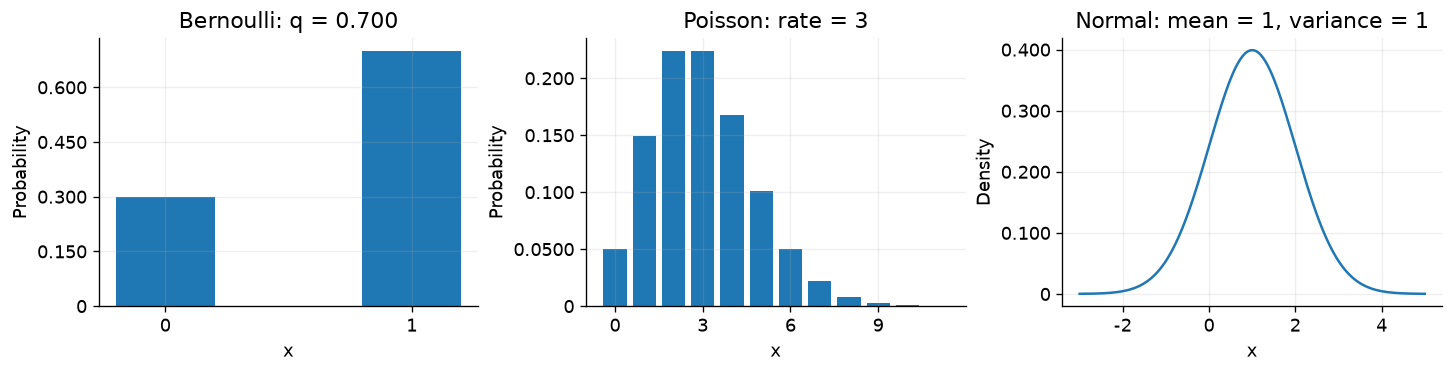

{'Bernoulliの確率': ['0.300', '0.700'], 'SciPyとの一致': '3種類とも確認済み'}


In [2]:
# 指数型の式を直接計算し、SciPyの確率分布と比較する。
fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")

q = 0.700
x_b = np.array([0, 1])
eta_b = np.log(q / (1 - q))
prob_b = np.exp(eta_b * x_b - np.logaddexp(0, eta_b))
np.testing.assert_allclose(prob_b, stats.bernoulli.pmf(x_b, q))
axes[0].bar(x_b, prob_b, width=0.400)
axes[0].set(xlabel="x", ylabel="Probability", title=f"Bernoulli: q = {sig3(q)}")

rate = 3
x_p = np.arange(12)
eta_p = np.log(rate)
# log(x!) = gammaln(x + 1)とすると、大きな階乗を作らずに済む。
prob_p = np.exp(eta_p * x_p - np.exp(eta_p) - gammaln(x_p + 1))
np.testing.assert_allclose(prob_p, stats.poisson.pmf(x_p, rate))
axes[1].bar(x_p, prob_p)
axes[1].set(xlabel="x", ylabel="Probability", title="Poisson: rate = 3")

mu = 1
x_n = np.linspace(-3, 5, 300)
density_n = np.exp(-x_n**2 / 2 + mu * x_n - mu**2 / 2) / np.sqrt(2 * np.pi)
np.testing.assert_allclose(density_n, stats.norm.pdf(x_n, loc=mu))
axes[2].plot(x_n, density_n)
axes[2].set(xlabel="x", ylabel="Density", title="Normal: mean = 1, variance = 1")
save_svg(fig, "01_distributions.svg", integer_x=True)
pprint({"Bernoulliの確率": [sig3(v) for v in prob_b],
        "SciPyとの一致": "3種類とも確認済み"})

## 2. 微分で平均と分散が得られる

$Z(\eta)=\sum_xh(x)e^{\eta T(x)}$と置くと$A=\log Z$である。

$$
\begin{aligned}
Z'&=\sum_xT(x)h(x)e^{\eta T(x)},\\
A'&=Z'/Z=\sum_xT(x)p(x;\eta)=\mathbb E[T(X)],\\
Z''&=\sum_xT(x)^2h(x)e^{\eta T(x)},\\
A''&=\frac{Z''Z-(Z')^2}{Z^2}\\
&=\mathbb E[T(X)^2]-\mathbb E[T(X)]^2
=\operatorname{Var}[T(X)]\geq0.
\end{aligned}
$$

平均と分散を得る対象は$T(X)$である。$T(x)=x$の場合に$X$自身の平均と分散になる。また、1観測のスコアは$\partial_\eta\log p=T(x)-A'$なので、フィッシャー情報量は$I(\eta)=\mathbb E[(T(X)-A')^2]=A''$となる。

私は、分布ごとに積分を覚えるよりも、この微分の関係から確認する方が整理しやすいと考える。図2ではベルヌーイ分布の$A$、平均、分散を比較する。

<IPython.core.display.Math object>

<IPython.core.display.Math object>

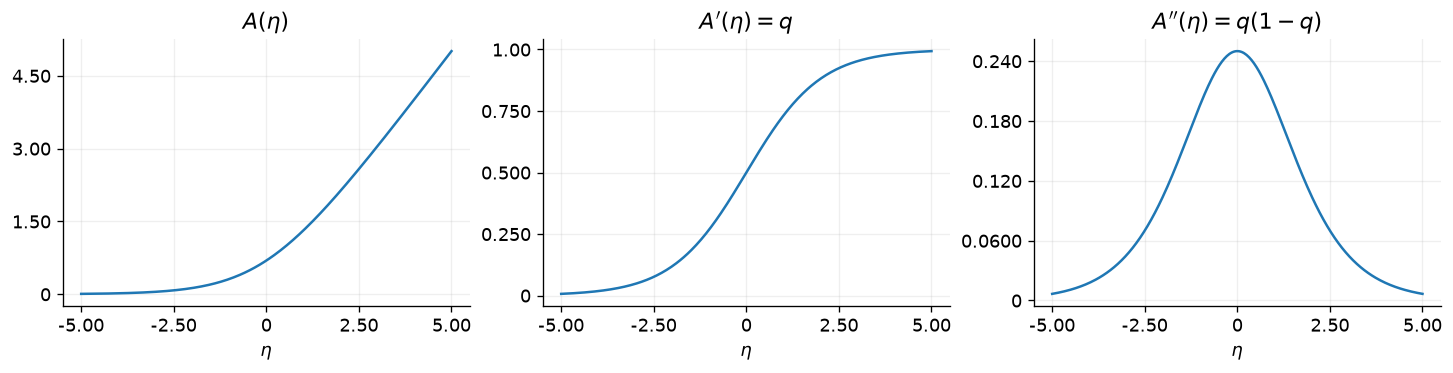

In [3]:
# SymPyで微分し、数式をLaTeXの出力欄に表示する。
eta = sp.symbols("eta", real=True)
A = sp.log(1 + sp.exp(eta))
mean_expr = sp.diff(A, eta)
var_expr = sp.factor(sp.diff(A, eta, 2))
assert sp.cancel(var_expr - mean_expr * (1 - mean_expr)) == 0
display(Math(r"A'(\eta)=" + sp.latex(mean_expr)))
display(Math(r"A''(\eta)=" + sp.latex(var_expr) + r"=q(1-q)"))

eta_grid = np.linspace(-5, 5, 300)
q_grid = expit(eta_grid)
curves = [np.logaddexp(0, eta_grid), q_grid, q_grid * (1 - q_grid)]
titles = [r"$A(\eta)$", r"$A'(\eta)=q$", r"$A''(\eta)=q(1-q)$"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")
for ax, values, title in zip(axes, curves, titles):
    ax.plot(eta_grid, values)
    ax.set(xlabel=r"$\eta$", title=title)
save_svg(fig, "02_log_partition.svg")

## 3. 十分統計量と最尤推定

独立同分布の$n$観測に対して$S=\sum_iT(x_i)$と置く。尤度は

$$
L(\eta)=\prod_i h(x_i)e^{\eta T(x_i)-A(\eta)}
=\left(\prod_i h(x_i)\right)e^{\eta S-nA(\eta)}
$$

と因数分解できる。$n$が既知なら、パラメータに関係するデータは$S$に集約される。この意味で$S$は十分統計量である。ただし、元のデータがモデルの適合度確認にも不要になるわけではない。

$$
\begin{aligned}
\ell(\eta)&=\log L(\eta)=\eta S-nA(\eta)+\sum_i\log h(x_i),\\
\ell'(\eta)&=S-nA'(\eta),\quad \ell''(\eta)=-nA''(\eta)\leq0,\\
\ell'(\hat\eta)=0&\quad\Rightarrow\quad A'(\hat\eta)=S/n.
\end{aligned}
$$

内部解が存在すれば、モデルの平均と標本平均が一致する。ベルヌーイ分布で10回中7回成功なら、$\hat q=7/10=0.700$、$\hat\eta=\log(7/3)$である。図3では順序の異なるデータの対数尤度が重なる。

{'n': 10, '成功数': 7, '推定確率': '0.700'}


<IPython.core.display.Math object>

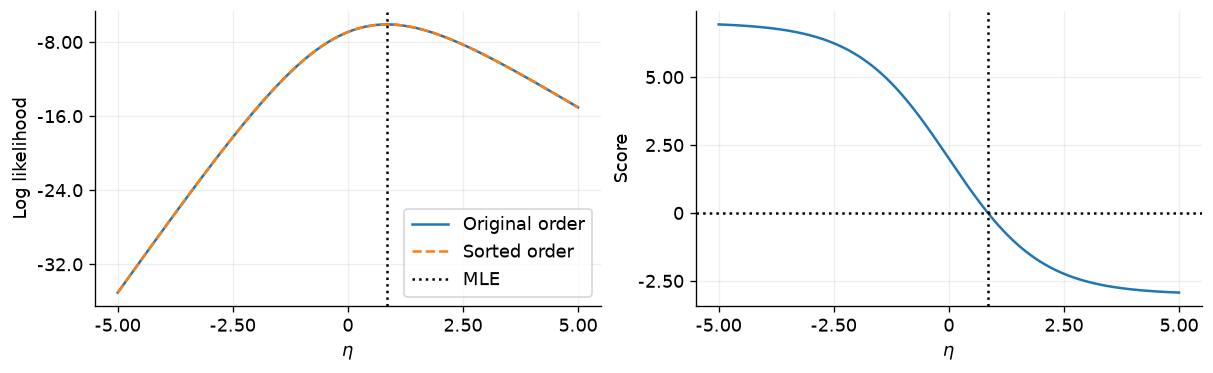

In [4]:
observed = np.array([1, 0, 1, 1, 0, 1, 1, 0, 1, 1])
reordered = np.sort(observed)
n = observed.size
successes = int(observed.sum())
q_hat = successes / n
eta_hat = np.log(q_hat / (1 - q_hat))

# 各観測からの計算と、成功数だけによる計算を照合する。
ll_full = (eta_grid[:, None] * observed - np.logaddexp(0, eta_grid[:, None])).sum(axis=1)
ll_reordered = (eta_grid[:, None] * reordered - np.logaddexp(0, eta_grid[:, None])).sum(axis=1)
ll_summary = eta_grid * successes - n * np.logaddexp(0, eta_grid)
np.testing.assert_allclose(ll_full, ll_summary)
np.testing.assert_allclose(ll_full, ll_reordered)
pprint({"n": n, "成功数": successes, "推定確率": sig3(q_hat)})
display(Math(r"\hat\eta=\log(7/3)\approx " + sig3(eta_hat)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
axes[0].plot(eta_grid, ll_full, label="Original order")
axes[0].plot(eta_grid, ll_reordered, "--", label="Sorted order")
axes[0].axvline(eta_hat, color="black", linestyle=":", label="MLE")
axes[0].set(xlabel=r"$\eta$", ylabel="Log likelihood")
axes[0].legend()
axes[1].plot(eta_grid, successes - n * expit(eta_grid))
axes[1].axhline(0, color="black", linestyle=":")
axes[1].axvline(eta_hat, color="black", linestyle=":")
axes[1].set(xlabel=r"$\eta$", ylabel="Score")
save_svg(fig, "03_sufficiency_mle.svg")

## 4. ベイズ更新も足し算になる

正規化可能な事前分布$\pi(\eta)\propto e^{a\eta-bA(\eta)}$を選ぶと、

$$
\pi(\eta\mid x_1,\ldots,x_n)
\propto e^{a\eta-bA(\eta)}e^{S\eta-nA(\eta)}
=e^{(a+S)\eta-(b+n)A(\eta)}
$$

となり、同じ形の分布で更新できる。これが共役性である。

成功確率$q$にベータ事前分布を置く場合も、指数を足せばよい。$\alpha,\beta>0$とする。

$$
\begin{aligned}
\pi(q\mid x_1,\ldots,x_n)
&\propto q^{\alpha-1}(1-q)^{\beta-1}q^S(1-q)^{n-S}\\
&=q^{\alpha+S-1}(1-q)^{\beta+n-S-1},\\
q\mid x_1,\ldots,x_n&\sim\operatorname{Beta}(\alpha+S,\beta+n-S).
\end{aligned}
$$

図4では$\operatorname{Beta}(2,2)$が$\operatorname{Beta}(9,5)$に更新される。追加観測のたびに成功数と失敗数を加えるだけなので、逐次処理にも使いやすい。

{'事後分布のパラメータ': [9, 5], '事後平均': '0.643'}


<IPython.core.display.Math object>

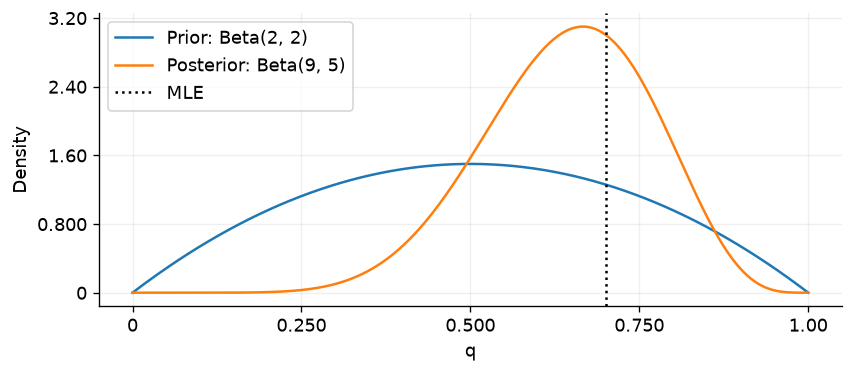

In [5]:
alpha, beta = 2, 2
alpha_post = alpha + successes
beta_post = beta + n - successes
prob_grid = np.linspace(0, 1, 400)
posterior_mean = stats.beta.mean(alpha_post, beta_post)
pprint({"事後分布のパラメータ": [alpha_post, beta_post],
        "事後平均": sig3(posterior_mean)})
display(Math(r"\mathbb E[q\mid x_1,\ldots,x_n]=\frac{9}{9+5}\approx "
             + sig3(posterior_mean)))

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(prob_grid, stats.beta.pdf(prob_grid, alpha, beta), label="Prior: Beta(2, 2)")
ax.plot(prob_grid, stats.beta.pdf(prob_grid, alpha_post, beta_post), label="Posterior: Beta(9, 5)")
ax.axvline(q_hat, color="black", linestyle=":", label="MLE")
ax.set(xlabel="q", ylabel="Density")
ax.legend()
save_svg(fig, "04_bayes_update.svg")

## 5. ロジスティック回帰との関係

説明変数を含むベクトル$\mathbf{x}_i$と係数$\mathbf{w}$から、$\eta_i=\mathbf{w}^{\mathsf T}\mathbf{x}_i$を作る。ベルヌーイ分布なら

<div>

$$q_i=A'(\eta_i)=\frac{1}{1+e^{-\mathbf{w}^{\mathsf T}\mathbf{x}_i}}$$

</div>

となる。シグモイド関数は、自然パラメータを成功確率に戻す変換である。条件付きで独立な観測の負の対数尤度$J$を微分すると、

$$
\begin{aligned}
J(\mathbf{w})&=-\sum_i\{y_i\log q_i+(1-y_i)\log(1-q_i)\}\\
&=\sum_i\{A(\eta_i)-y_i\eta_i\},\\
\nabla J&=\sum_i\{A'(\eta_i)-y_i\}\mathbf{x}_i
=\sum_i(q_i-y_i)\mathbf{x}_i,\\
\nabla^2J&=\sum_iq_i(1-q_i)\mathbf{x}_i\mathbf{x}_i^{\mathsf T}\succeq0.
\end{aligned}
$$

したがってこの損失は凸である。次のコードは合成データを作り、勾配とヘッセ行列を渡して最小化する。図5に推定確率、図6に損失の推移を示す。

{'推定係数': ['-0.545', '1.12'], '最適化成功': True, '負の対数尤度': '103'}


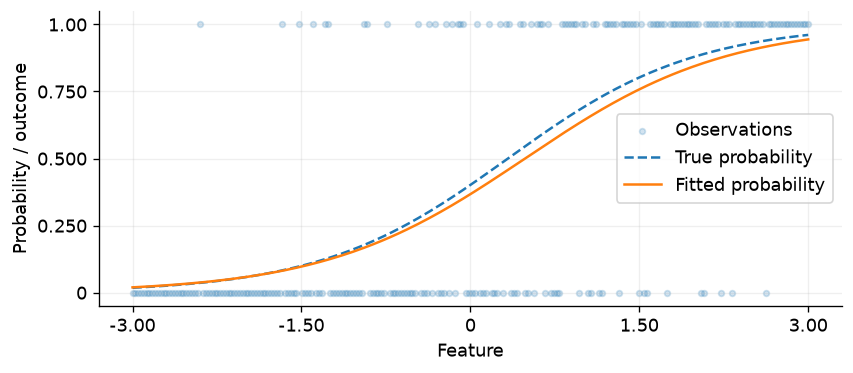

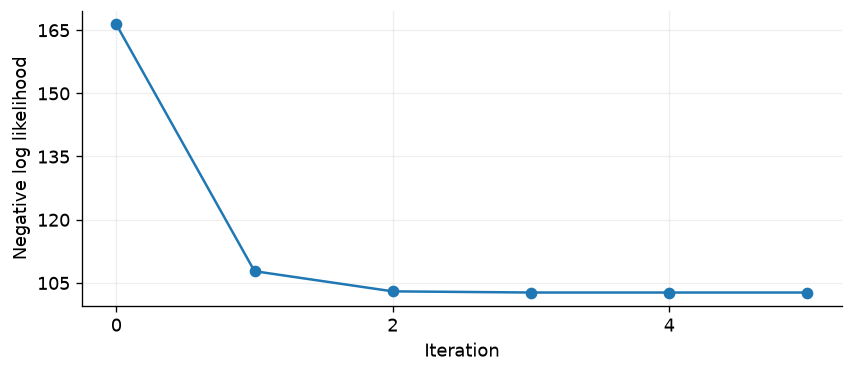

In [6]:
rng = np.random.default_rng(104)
feature = np.linspace(-3, 3, 240)
# 先頭列の1が切片に対応する。
X = np.column_stack([np.ones(feature.size), feature])
true_w = np.array([-0.400, 1.20])
true_prob = expit(X @ true_w)
labels = rng.binomial(1, true_prob)


def loss(w):
    z = X @ w
    # log(1 + exp(z))を安定に計算する。
    return float(np.sum(np.logaddexp(0, z) - labels * z))


def gradient(w):
    return X.T @ (expit(X @ w) - labels)


def hessian(w):
    p = expit(X @ w)
    return X.T @ ((p * (1 - p))[:, None] * X)


start = np.zeros(X.shape[1])
loss_history = [loss(start)]
result = minimize(loss, start, jac=gradient, hess=hessian,
                  method="trust-exact", callback=lambda w: loss_history.append(loss(w)),
                  options={"gtol": 1.00e-6})
assert result.success, result.message
assert np.linalg.norm(gradient(result.x)) < 1.00e-6
pprint({"最適化成功": bool(result.success),
        "推定係数": [sig3(v) for v in result.x],
        "負の対数尤度": sig3(result.fun)})

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.scatter(feature, labels, alpha=0.200, s=12, label="Observations")
ax.plot(feature, true_prob, "--", label="True probability")
ax.plot(feature, expit(X @ result.x), label="Fitted probability")
ax.set(xlabel="Feature", ylabel="Probability / outcome")
ax.legend()
save_svg(fig, "05_logistic_fit.svg")

fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(np.arange(len(loss_history)), loss_history, "o-")
ax.set(xlabel="Iteration", ylabel="Negative log likelihood")
save_svg(fig, "06_optimization.svg", integer_x=True)

正準リンクを用いる一般化線形モデルでは、同じ考え方で分布を選び直せる。ポアソン分布なら条件付き平均は$e^{\eta_i}$、分散1の正規分布なら$\eta_i$となる。

ただし、凸性は有限な最適解の存在を保証しない。ベルヌーイ標本が全成功・全失敗なら自然パラメータの最尤推定値は発散し、ロジスティック回帰でも完全分離時に同じ問題が起こる。

## 結論

この記事では、指数型分布族の共通形式から、モーメント計算、十分統計量、推定、ベイズ更新、回帰の関係を確認した。

重要なのは、対数分配関数の微分と統計量の和で多くの計算を記述できる点である。共通の実装を使える一方、分布の仮定や推定解の存在は別途確認する必要がある。

参考文献：定義と微分公式は [Will Fithian, Exponential Families](https://stat210a.berkeley.edu/fall-2025/reader/exponential-families.html)、共役性は [Bayes Estimation](https://stat210a.berkeley.edu/fall-2025/reader/bayes-estimation.html)、回帰との関係は [Ng・Ma, CS229 Lecture Notes, 第3節](https://cs229.stanford.edu/notes2022fall/main_notes.pdf)を参照した。